# Proyecto 2 - Pruebas Saber 11 (2020-2)

**Caso de estudio:** resultados de las pruebas Saber 11 del segundo semestre de 2020 (ICFES, datos.gov.co).

**Preguntas de negocio:**
1. ¿Cuáles son los 10 departamentos con mejor puntaje global promedio?
2. ¿Quién obtiene mejor puntaje global, los colegios oficiales o los no oficiales?
3. ¿Cómo cambia el puntaje global según el nivel socioeconómico (estrato)?
4. ¿Qué región de Colombia tiene el mejor y el peor puntaje en inglés?
5. ¿Hay diferencia entre hombres y mujeres en matemáticas?

Este notebook corre en EMR (JupyterHub, kernel **PySpark**). Lee la zona **trusted** que deja el job de Glue,
responde las preguntas con **SparkSQL** (punto 6) y con **DataFrames** (punto 7), guarda las respuestas en la zona
**refined** y hace las gráficas (punto 8).

In [1]:
BUCKET = "saber11-datalake-mm"   # cambiar por el nombre de tu bucket
RAW = "s3://" + BUCKET + "/raw"
TRUSTED = "s3://" + BUCKET + "/trusted"
REFINED = "s3://" + BUCKET + "/refined"

spark

Starting Spark application


ID,YARN Application ID,Kind,State,Spark UI,Driver log,User,Current session?
0,application_1794867617116_0007,pyspark,idle,Link,Link,None,✔


FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

SparkSession available as 'spark'.


FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

## Cargar la zona trusted

In [2]:
saber = spark.read.parquet(TRUSTED + "/saber11/")
deptos = spark.read.parquet(TRUSTED + "/departamentos/")
estratos = spark.read.parquet(TRUSTED + "/estratos/")

saber.createOrReplaceTempView("saber11")
deptos.createOrReplaceTempView("departamentos")
estratos.createOrReplaceTempView("estratos")

saber.printSchema()
saber.show(5)

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

root
 |-- cod_depto: integer (nullable = true)
 |-- departamento: string (nullable = true)
 |-- naturaleza: string (nullable = true)
 |-- genero: string (nullable = true)
 |-- estrato: string (nullable = true)
 |-- puntaje_matematicas: integer (nullable = true)
 |-- puntaje_ingles: integer (nullable = true)
 |-- puntaje_global: integer (nullable = true)

+---------+------------+----------+------+---------+-------------------+--------------+--------------+
|cod_depto|departamento|naturaleza|genero|  estrato|puntaje_matematicas|puntaje_ingles|puntaje_global|
+---------+------------+----------+------+---------+-------------------+--------------+--------------+
|       11|      BOGOTÁ|NO OFICIAL|     F|Estrato 2|                 40|            41|           205|
|       11|      BOGOTÁ|NO OFICIAL|     M|Estrato 2|                 59|            57|           314|
|       11|      BOGOTÁ|NO OFICIAL|     F|Estrato 2|                 54|            30|           227|
|       23|     CORDOBA| 

In [3]:
# Verificacion: raw y trusted deben tener el mismo numero de filas
raw_saber = spark.read.csv(RAW + "/saber11/", header=True)
print("filas raw:", raw_saber.count(), "| filas trusted:", saber.count())
print("departamentos:", deptos.count(), "| estratos:", estratos.count())

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

filas raw: 504872 | filas trusted: 504872
departamentos: 33 | estratos: 7

In [4]:
# Las tablas que creo el crawler de Glue tambien se ven desde Spark (catalogo compartido)
spark.sql("SHOW TABLES IN saber11_db").show()

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

+----------+-------------+-----------+
| namespace|    tableName|isTemporary|
+----------+-------------+-----------+
|saber11_db|departamentos|      false|
|saber11_db|     estratos|      false|
|saber11_db|estratos_hive|      false|
|saber11_db|      saber11|      false|
|          |departamentos|       true|
|          |     estratos|       true|
|          |      saber11|       true|
+----------+-------------+-----------+

## Punto 6: consultas con SparkSQL (las mismas que en Athena y Hive)

In [5]:
# Pregunta 1: top 10 departamentos por puntaje global
spark.sql("""
SELECT departamento, ROUND(AVG(puntaje_global), 1) AS promedio_global
FROM saber11
GROUP BY departamento
ORDER BY promedio_global DESC
LIMIT 10
""").show()

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

+---------------+---------------+
|   departamento|promedio_global|
+---------------+---------------+
|         BOGOTÁ|          267.0|
|      SANTANDER|          264.6|
|         BOYACA|          261.0|
|   CUNDINAMARCA|          258.3|
|NORTE SANTANDER|          256.9|
|        QUINDIO|          253.6|
|      RISARALDA|          253.3|
|           META|          251.1|
|          HUILA|          250.7|
|         CALDAS|          250.4|
+---------------+---------------+

In [6]:
# Pregunta 2: oficiales vs no oficiales
spark.sql("""
SELECT naturaleza, ROUND(AVG(puntaje_global), 1) AS promedio_global
FROM saber11
GROUP BY naturaleza
ORDER BY promedio_global DESC
""").show()

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

+----------+---------------+
|naturaleza|promedio_global|
+----------+---------------+
|NO OFICIAL|          270.8|
|   OFICIAL|          241.8|
+----------+---------------+

In [7]:
# Pregunta 3: nivel socioeconomico (estratos viene del archivo de la EC2)
spark.sql("""
SELECT e.nivel, ROUND(AVG(s.puntaje_global), 1) AS promedio_global
FROM saber11 s
JOIN estratos e ON s.estrato = e.estrato
GROUP BY e.nivel
ORDER BY promedio_global DESC
""").show()

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

+-----------+---------------+
|      nivel|promedio_global|
+-----------+---------------+
|      Medio|          264.3|
|       Alto|          264.2|
|       Bajo|          244.3|
|Sin estrato|          209.6|
+-----------+---------------+

In [8]:
# Pregunta 4: ingles por region (departamentos viene de la base de datos)
spark.sql("""
SELECT d.region, ROUND(AVG(s.puntaje_ingles), 1) AS promedio_ingles
FROM saber11 s
JOIN departamentos d ON s.cod_depto = d.codigo
GROUP BY d.region
ORDER BY promedio_ingles DESC
""").show()

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

+---------+---------------+
|   region|promedio_ingles|
+---------+---------------+
|  Insular|           51.9|
|   Andina|           48.3|
|Orinoquia|           46.2|
| Pacifica|           45.1|
|   Caribe|           44.7|
| Amazonia|           43.7|
+---------+---------------+

In [9]:
# Pregunta 5: matematicas por genero
spark.sql("""
SELECT genero, ROUND(AVG(puntaje_matematicas), 1) AS promedio_matematicas
FROM saber11
WHERE genero IN ('F', 'M')
GROUP BY genero
ORDER BY promedio_matematicas DESC
""").show()

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

+------+--------------------+
|genero|promedio_matematicas|
+------+--------------------+
|     M|                52.6|
|     F|                49.7|
+------+--------------------+

## Punto 7: las mismas preguntas con DataFrames (PySpark)

In [10]:
from pyspark.sql import functions as F

# Pregunta 1
r1 = (saber.groupBy("departamento")
      .agg(F.round(F.avg("puntaje_global"), 1).alias("promedio_global"))
      .orderBy(F.desc("promedio_global"))
      .limit(10))
r1.show()

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

+---------------+---------------+
|   departamento|promedio_global|
+---------------+---------------+
|         BOGOTÁ|          267.0|
|      SANTANDER|          264.6|
|         BOYACA|          261.0|
|   CUNDINAMARCA|          258.3|
|NORTE SANTANDER|          256.9|
|        QUINDIO|          253.6|
|      RISARALDA|          253.3|
|           META|          251.1|
|          HUILA|          250.7|
|         CALDAS|          250.4|
+---------------+---------------+

In [11]:
# Pregunta 2
r2 = (saber.groupBy("naturaleza")
      .agg(F.round(F.avg("puntaje_global"), 1).alias("promedio_global"))
      .orderBy(F.desc("promedio_global")))
r2.show()

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

+----------+---------------+
|naturaleza|promedio_global|
+----------+---------------+
|NO OFICIAL|          270.8|
|   OFICIAL|          241.8|
+----------+---------------+

In [12]:
# Pregunta 3 (join con estratos)
r3 = (saber.join(estratos, "estrato")
      .groupBy("nivel")
      .agg(F.round(F.avg("puntaje_global"), 1).alias("promedio_global"))
      .orderBy(F.desc("promedio_global")))
r3.show()

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

+-----------+---------------+
|      nivel|promedio_global|
+-----------+---------------+
|      Medio|          264.3|
|       Alto|          264.2|
|       Bajo|          244.3|
|Sin estrato|          209.6|
+-----------+---------------+

In [13]:
# Pregunta 4 (join con departamentos)
r4 = (saber.join(deptos, saber.cod_depto == deptos.codigo)
      .groupBy("region")
      .agg(F.round(F.avg("puntaje_ingles"), 1).alias("promedio_ingles"))
      .orderBy(F.desc("promedio_ingles")))
r4.show()

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

+---------+---------------+
|   region|promedio_ingles|
+---------+---------------+
|  Insular|           51.9|
|   Andina|           48.3|
|Orinoquia|           46.2|
| Pacifica|           45.1|
|   Caribe|           44.7|
| Amazonia|           43.7|
+---------+---------------+

In [14]:
# Pregunta 5
r5 = (saber.filter(F.col("genero").isin("F", "M"))
      .groupBy("genero")
      .agg(F.round(F.avg("puntaje_matematicas"), 1).alias("promedio_matematicas"))
      .orderBy(F.desc("promedio_matematicas")))
r5.show()

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

+------+--------------------+
|genero|promedio_matematicas|
+------+--------------------+
|     M|                52.6|
|     F|                49.7|
+------+--------------------+

## Guardar las respuestas en la zona refined (las lee la Lambda)

In [15]:
respuestas = {"p1": r1, "p2": r2, "p3": r3, "p4": r4, "p5": r5}

for nombre, df in respuestas.items():
    df.coalesce(1).write.mode("overwrite").option("header", "true").csv(REFINED + "/" + nombre + "/")
    print("guardado", nombre)

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

guardado p1
guardado p2
guardado p3
guardado p4
guardado p5

## Punto 8: gráficas con matplotlib

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

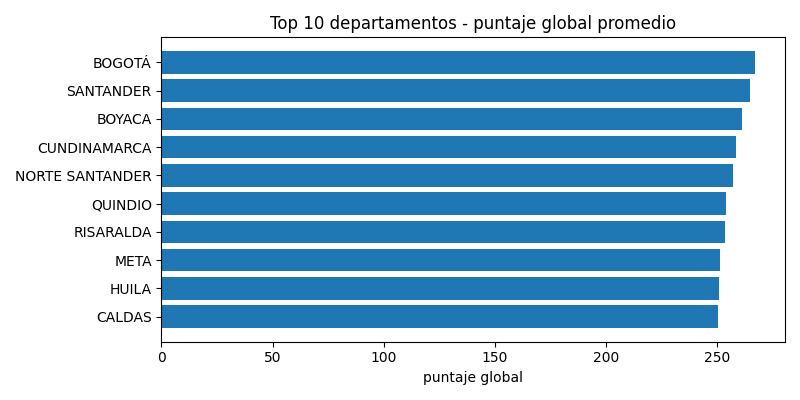

In [16]:
import matplotlib.pyplot as plt

datos = r1.toPandas()
plt.figure(figsize=(8, 4))
plt.barh(datos["departamento"], datos["promedio_global"])
plt.gca().invert_yaxis()
plt.title("Top 10 departamentos - puntaje global promedio")
plt.xlabel("puntaje global")
plt.tight_layout()
%matplot plt

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

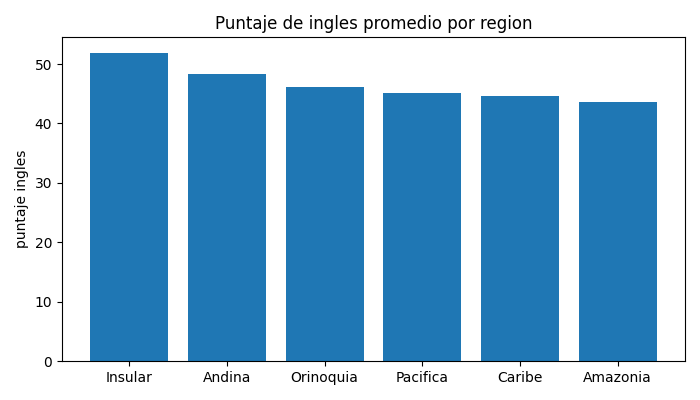

In [17]:
datos = r4.toPandas()
plt.figure(figsize=(7, 4))
plt.bar(datos["region"], datos["promedio_ingles"])
plt.title("Puntaje de ingles promedio por region")
plt.ylabel("puntaje ingles")
plt.tight_layout()
%matplot plt